# Public-ranking intended-use evaluation

**TL;DR:** Prediction remains a valid generalization test. The added ranking-specific evidence shows that LOOPR is poor at the sparse edge, competitive in the dense core, and unusually robust under several leaderboard attacks. It does not dominate every baseline.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
OUTPUT = Path.cwd()
TABLES = OUTPUT / 'tables'
FIGURES = OUTPUT / 'figures'
print(OUTPUT)

/tmp/sendouq_part1_publish/analysis/part1/intended_use/output


## Requirements profile

No composite score is formed; arrows in the column names show direction.

In [2]:
profile = pd.read_csv(TABLES / 'requirements_profile.csv')
display(profile)

,method,dense_core32_log_loss,dense_core32_ordering_accuracy,historical_seed_concordance,monthly_mean_membership_retention,monthly_mean_retained_spearman,monthly_median_p90_rank_movement,important_event_worst_top100_retention,important_event_largest_rank_shift,weak_50_win_median_score_change_sd,weak_to_strong_response_ratio,volume_5x_p90_abs_score_change_sd,thin_50_top100_retention,thin_50_target_pair_order_retention,thin_50_p90_abs_score_change_sd,equal_record_schedule_gap_sd
0,LOOPR,0.485770,0.765476,0.841435,0.838462,0.964688,12.8,0.99,14.0,0.066136,0.096109,0.124003,0.950,0.938449,0.238117,0.805293
1,OpenSkill μ,0.481391,0.763353,0.845307,0.852308,0.914085,19.6,0.97,47.0,0.114544,0.108798,0.408898,0.885,0.889873,0.557569,0.895392
2,OpenSkill ordinal,0.497540,0.748850,0.867238,0.877692,0.918085,21.0,0.97,33.0,0.074485,0.093566,0.224997,0.910,0.921519,0.465150,0.627010
3,Bradley–Terry (L2),0.481932,0.761938,0.850382,0.887692,0.947820,15.5,0.98,34.0,0.090403,0.074637,0.229675,0.880,0.902848,0.511981,0.468073
4,90-day win rate,0.552628,0.714185,0.755127,0.573846,0.588959,40.2,0.95,676.0,1.585383,0.905686,0.634248,0.760,0.816139,0.734681,0.129296


## Graph support

Support is based on the pre-event opponent graph, independent of scores and outcome direction.

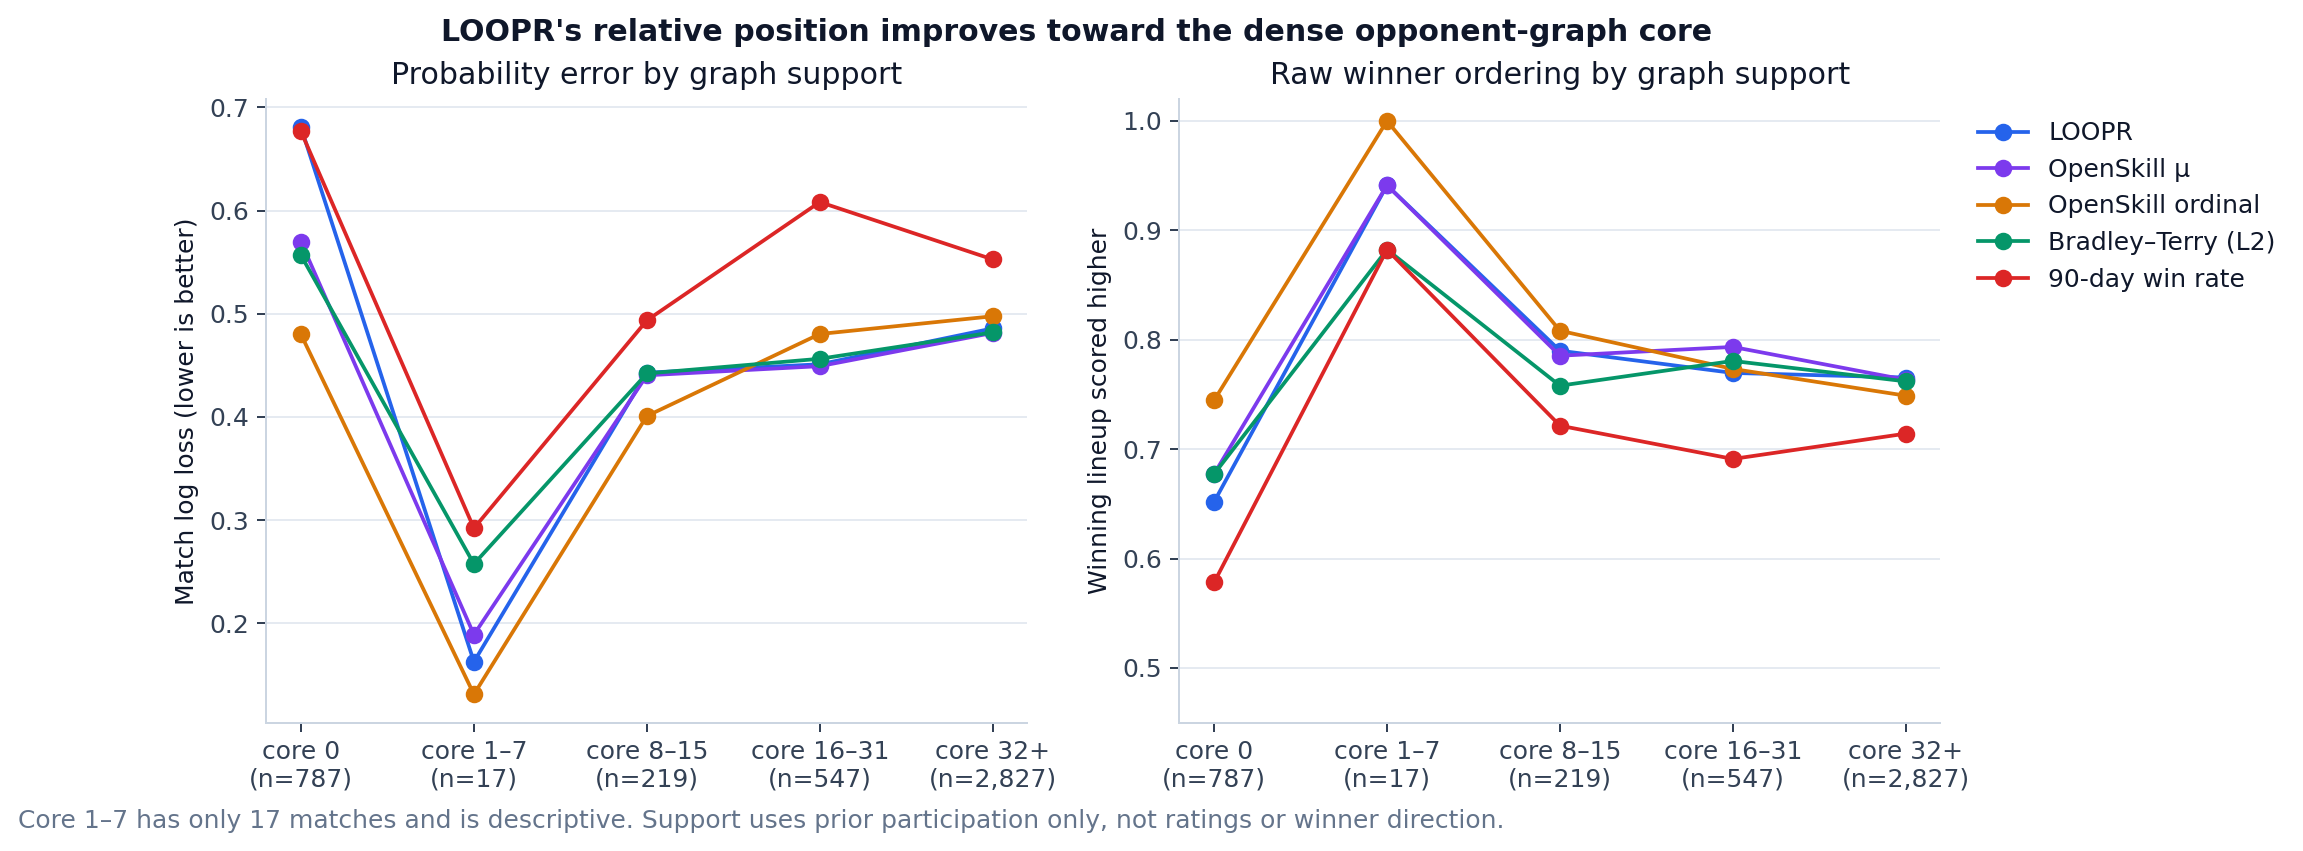

,support_band,minimum_core,maximum_core,method,matches,tournaments,match_coverage,match_micro_log_loss,tournament_macro_log_loss,ordering_accuracy,brier_score,method_minus_loopr_log_loss,log_loss_difference_ci_low,log_loss_difference_ci_high,method_minus_loopr_accuracy,accuracy_difference_ci_low,accuracy_difference_ci_high,support_warning
0,core 0,0,0.0,LOOPR,787,85,0.178986,0.680589,0.619443,0.651842,0.231014,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN
1,core 0,0,0.0,OpenSkill μ,787,85,0.178986,0.569703,0.529372,0.677255,0.196093,-0.090071,-0.137421,-0.048096,0.033041,-0.005418,0.074615,NaN
2,core 0,0,0.0,OpenSkill ordinal,787,85,0.178986,0.479891,0.441837,0.744600,0.160603,-0.177606,-0.265370,-0.091634,0.095852,0.050801,0.142318,NaN
3,core 0,0,0.0,Bradley–Terry (L2),787,85,0.178986,0.556595,0.528361,0.677255,0.190907,-0.091082,-0.145704,-0.040096,0.026443,-0.005707,0.059204,NaN
4,core 0,0,0.0,90-day win rate,787,85,0.178986,0.676643,0.654549,0.578145,0.236952,0.035106,-0.033014,0.095365,-0.100134,-0.150206,-0.054681,NaN
5,core 0,0,0.0,Chance (0.5),787,85,0.178986,0.693147,0.693147,0.500000,0.250000,0.073704,-0.014475,0.154574,-0.185514,-0.238095,-0.132899,NaN
6,core 1–7,1,7.0,LOOPR,17,7,0.003866,0.162755,0.157049,0.941176,0.047341,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,descriptive only: fewer than 200 matches or fi...
7,core 1–7,1,7.0,OpenSkill μ,17,7,0.003866,0.189049,0.172324,0.941176,0.048589,0.015276,-0.142893,0.140947,0.035714,-0.107143,0.214286,descriptive only: fewer than 200 matches or fi...
8,core 1–7,1,7.0,OpenSkill ordinal,17,7,0.003866,0.131197,0.115111,1.000000,0.029681,-0.041938,-0.196753,0.065343,0.071429,0.000000,0.214286,descriptive only: fewer than 200 matches or fi...
9,core 1–7,1,7.0,Bradley–Terry (L2),17,7,0.003866,0.257538,0.244489,0.882353,0.076800,0.087440,-0.059980,0.226534,-0.035714,-0.250000,0.178571,descriptive only: fewer than 200 matches or fi...


In [3]:
display(Image(filename=str(FIGURES / '01_graph_support.png')))
display(pd.read_csv(TABLES / 'prediction_by_support_band.csv'))

## Historical tournament seeds

Stored seeds are audited as organizer-controlled artifacts, not ground truth.

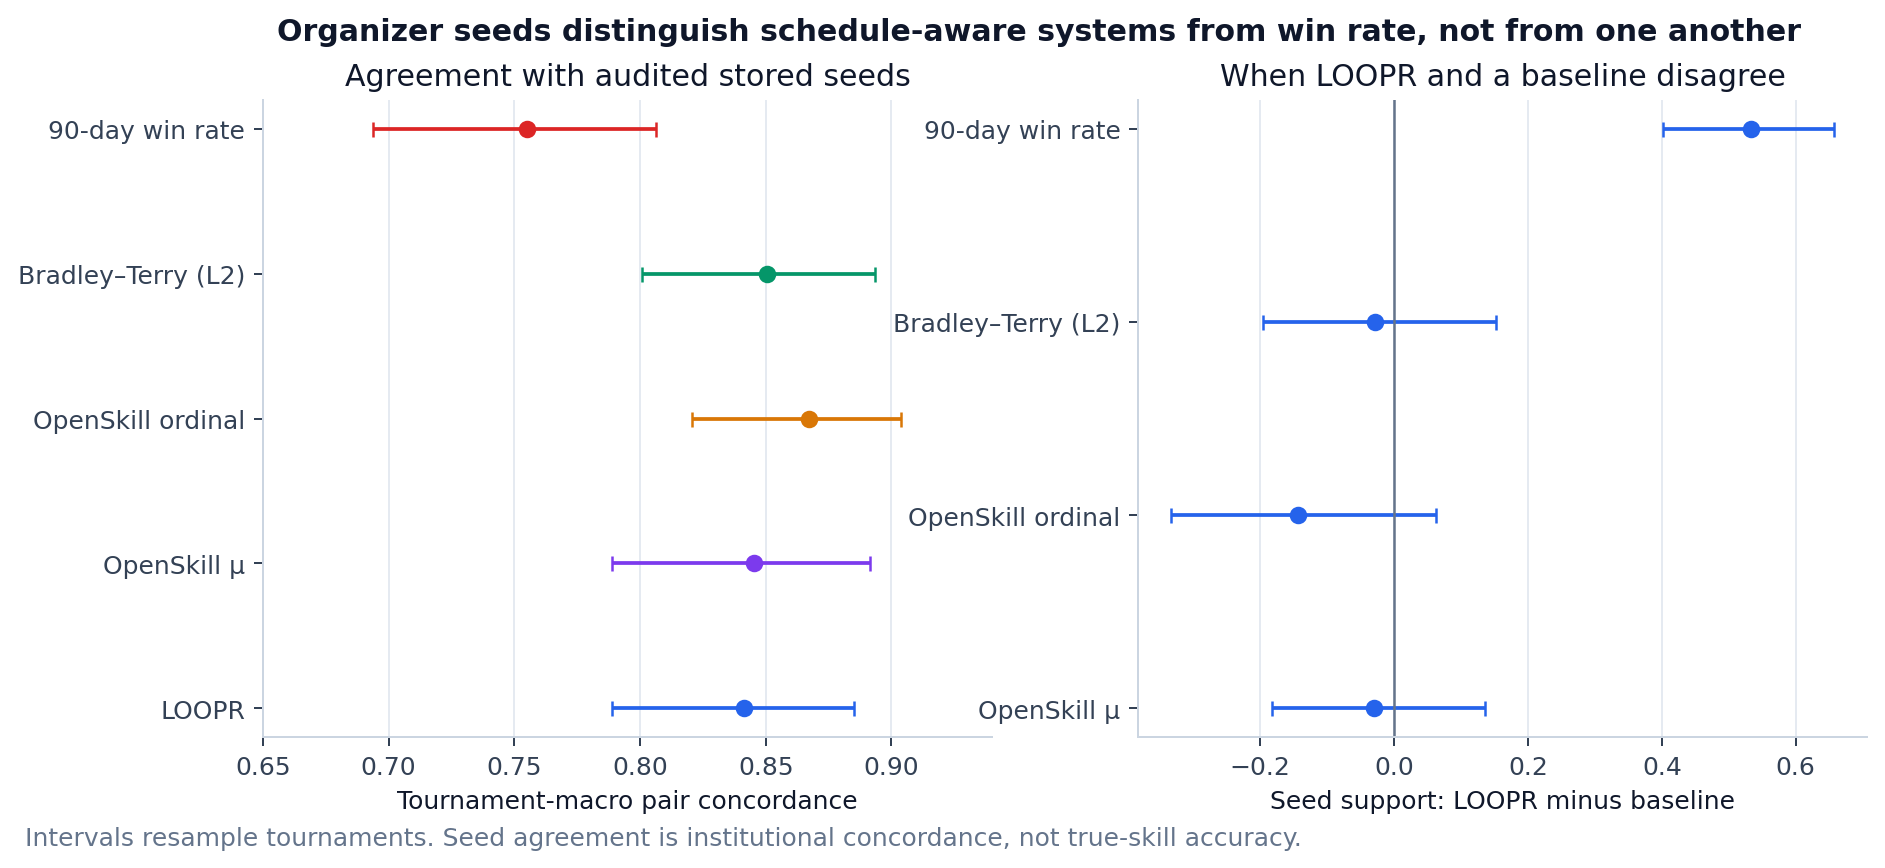

,best_seed_in_match_band,matches,tournaments,match_micro_higher_seed_win_rate,tournament_macro_higher_seed_win_rate,macro_ci_low,macro_ci_high
0,top 4,1791,124,0.755444,0.753085,0.731932,0.774664
1,5-8,928,124,0.716595,0.711022,0.670852,0.750620
2,9+,743,72,0.717362,0.692266,0.629159,0.752769


In [4]:
display(Image(filename=str(FIGURES / '02_historical_seeds.png')))
display(pd.read_csv(TABLES / 'seed_outcome_by_band.csv'))

## Stability, robustness, and adversarial behavior

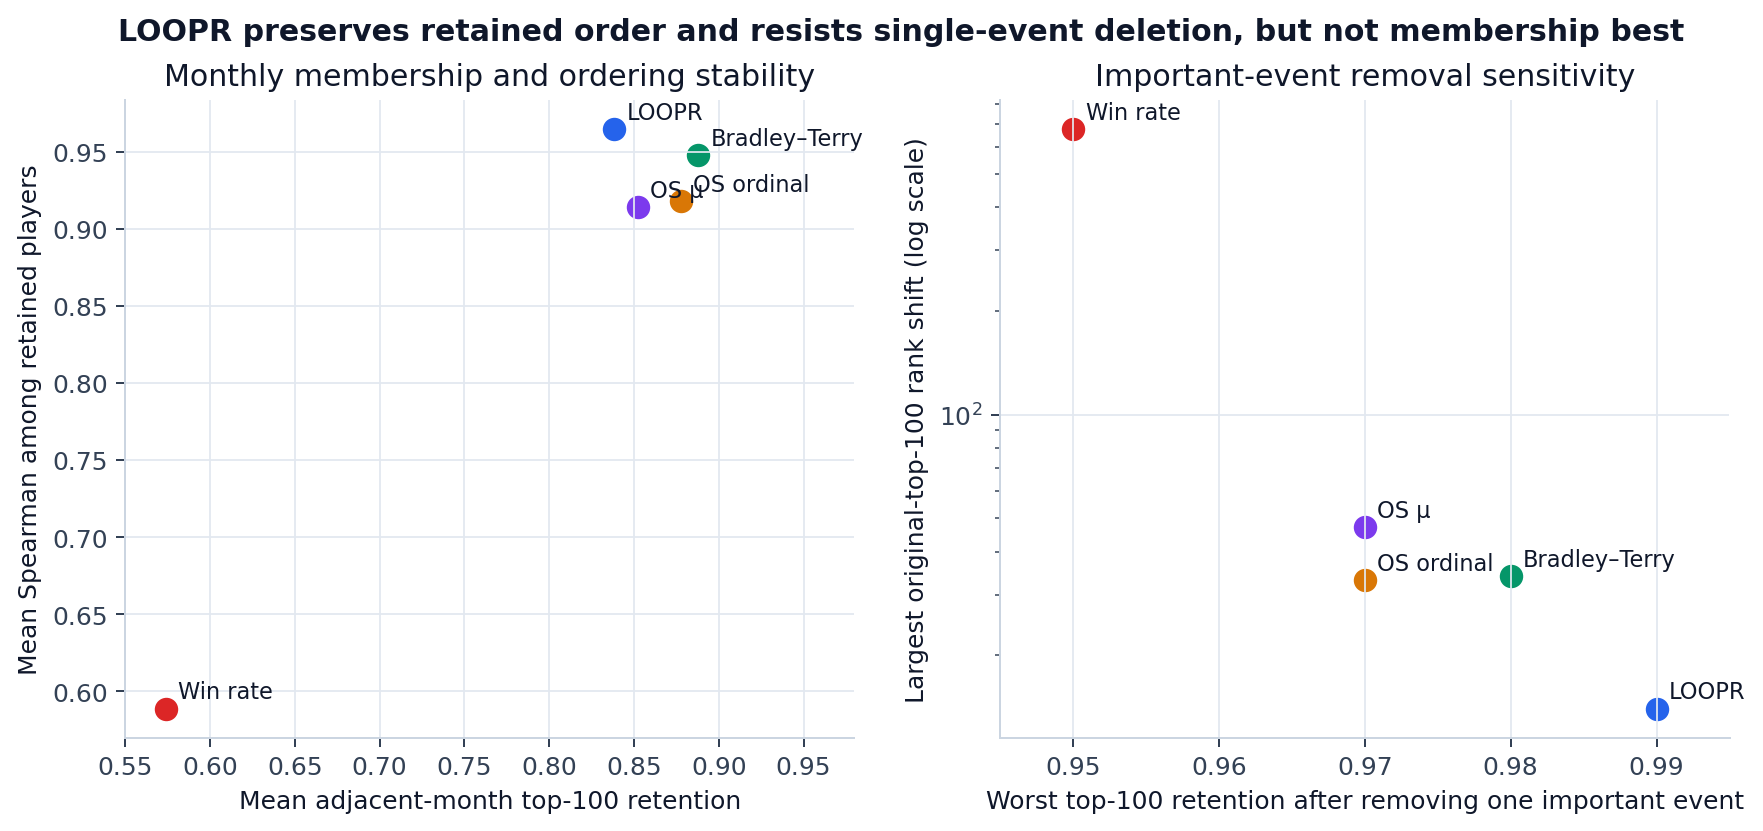

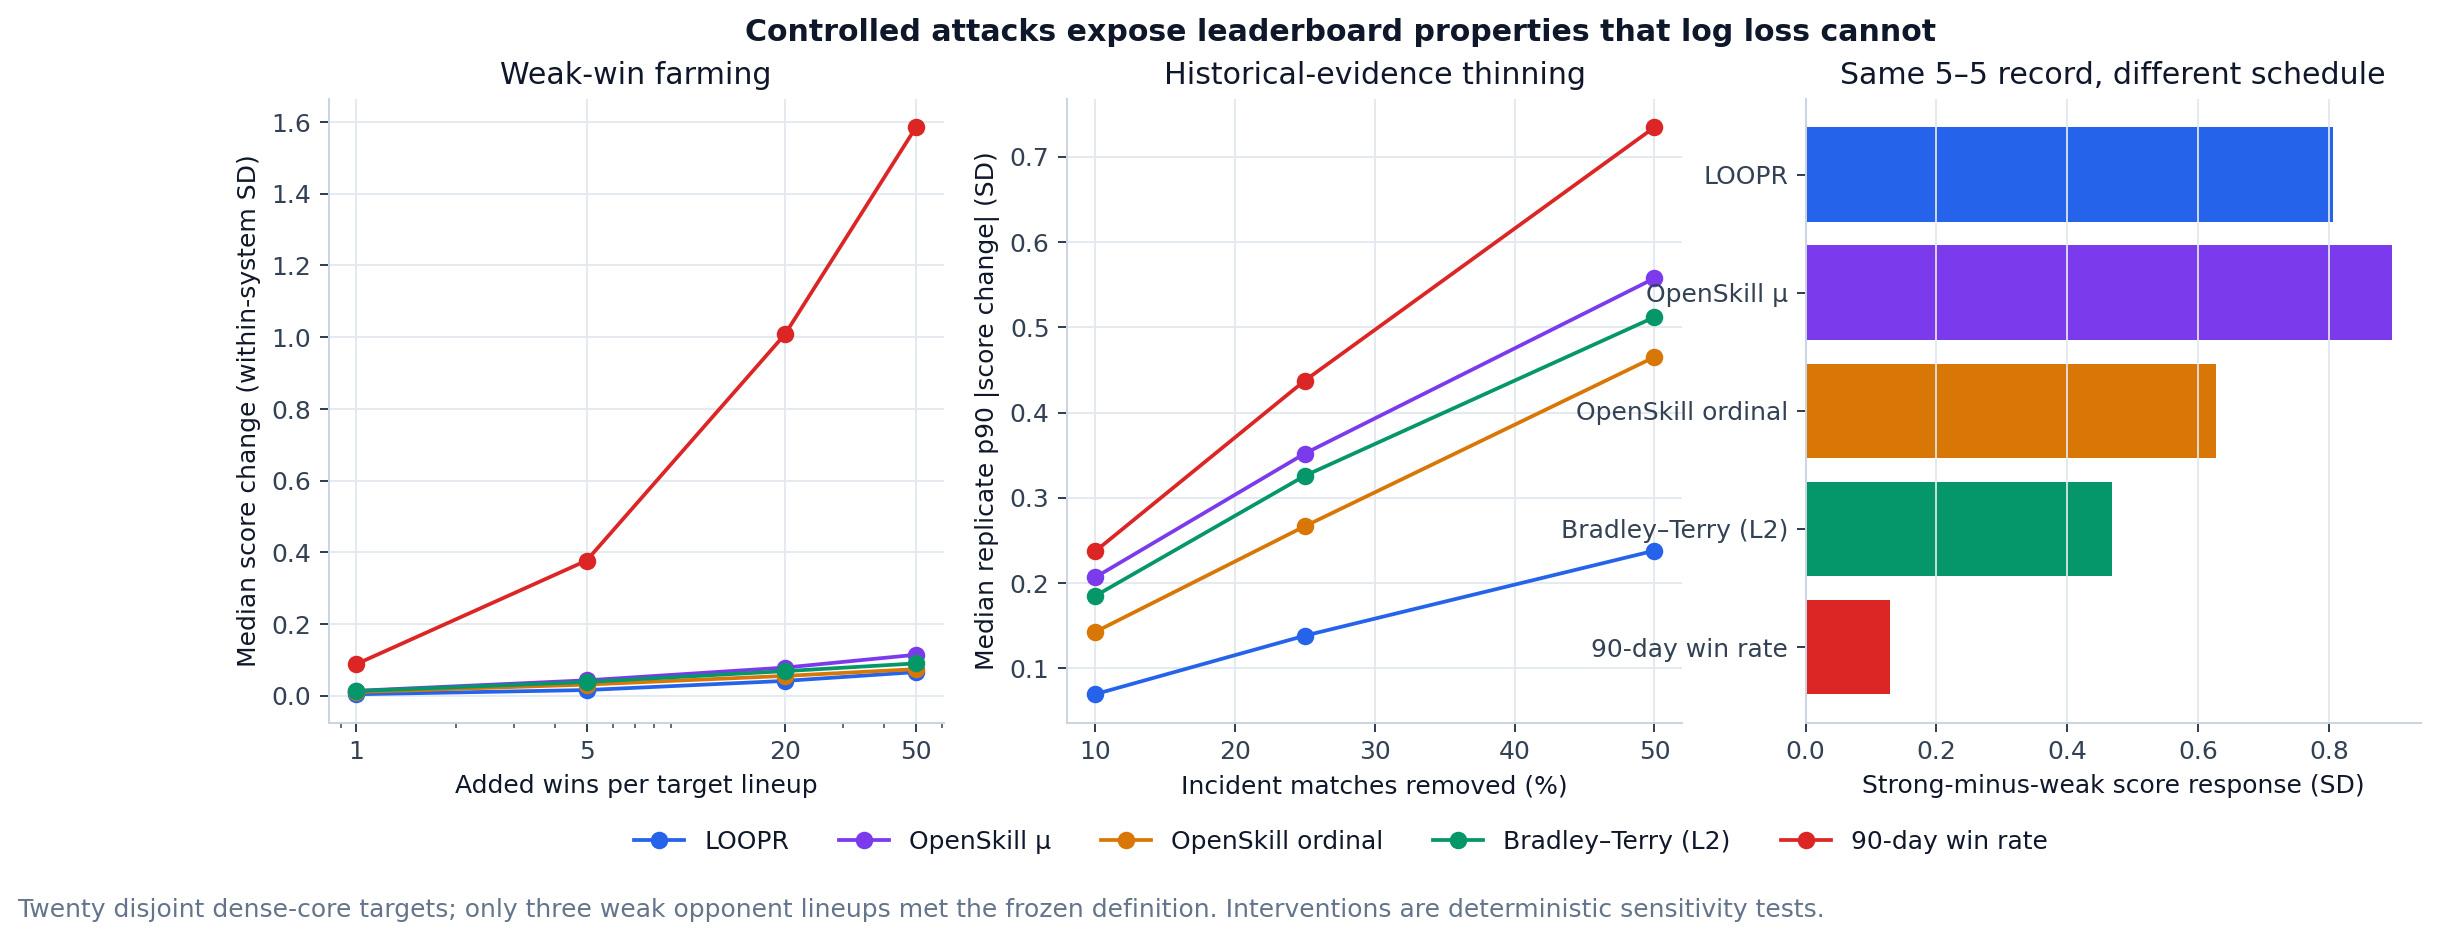

In [5]:
display(Image(filename=str(FIGURES / '03_stability_robustness.png')))
display(Image(filename=str(FIGURES / '04_adversarial_tests.png')))

## Plus decomposition

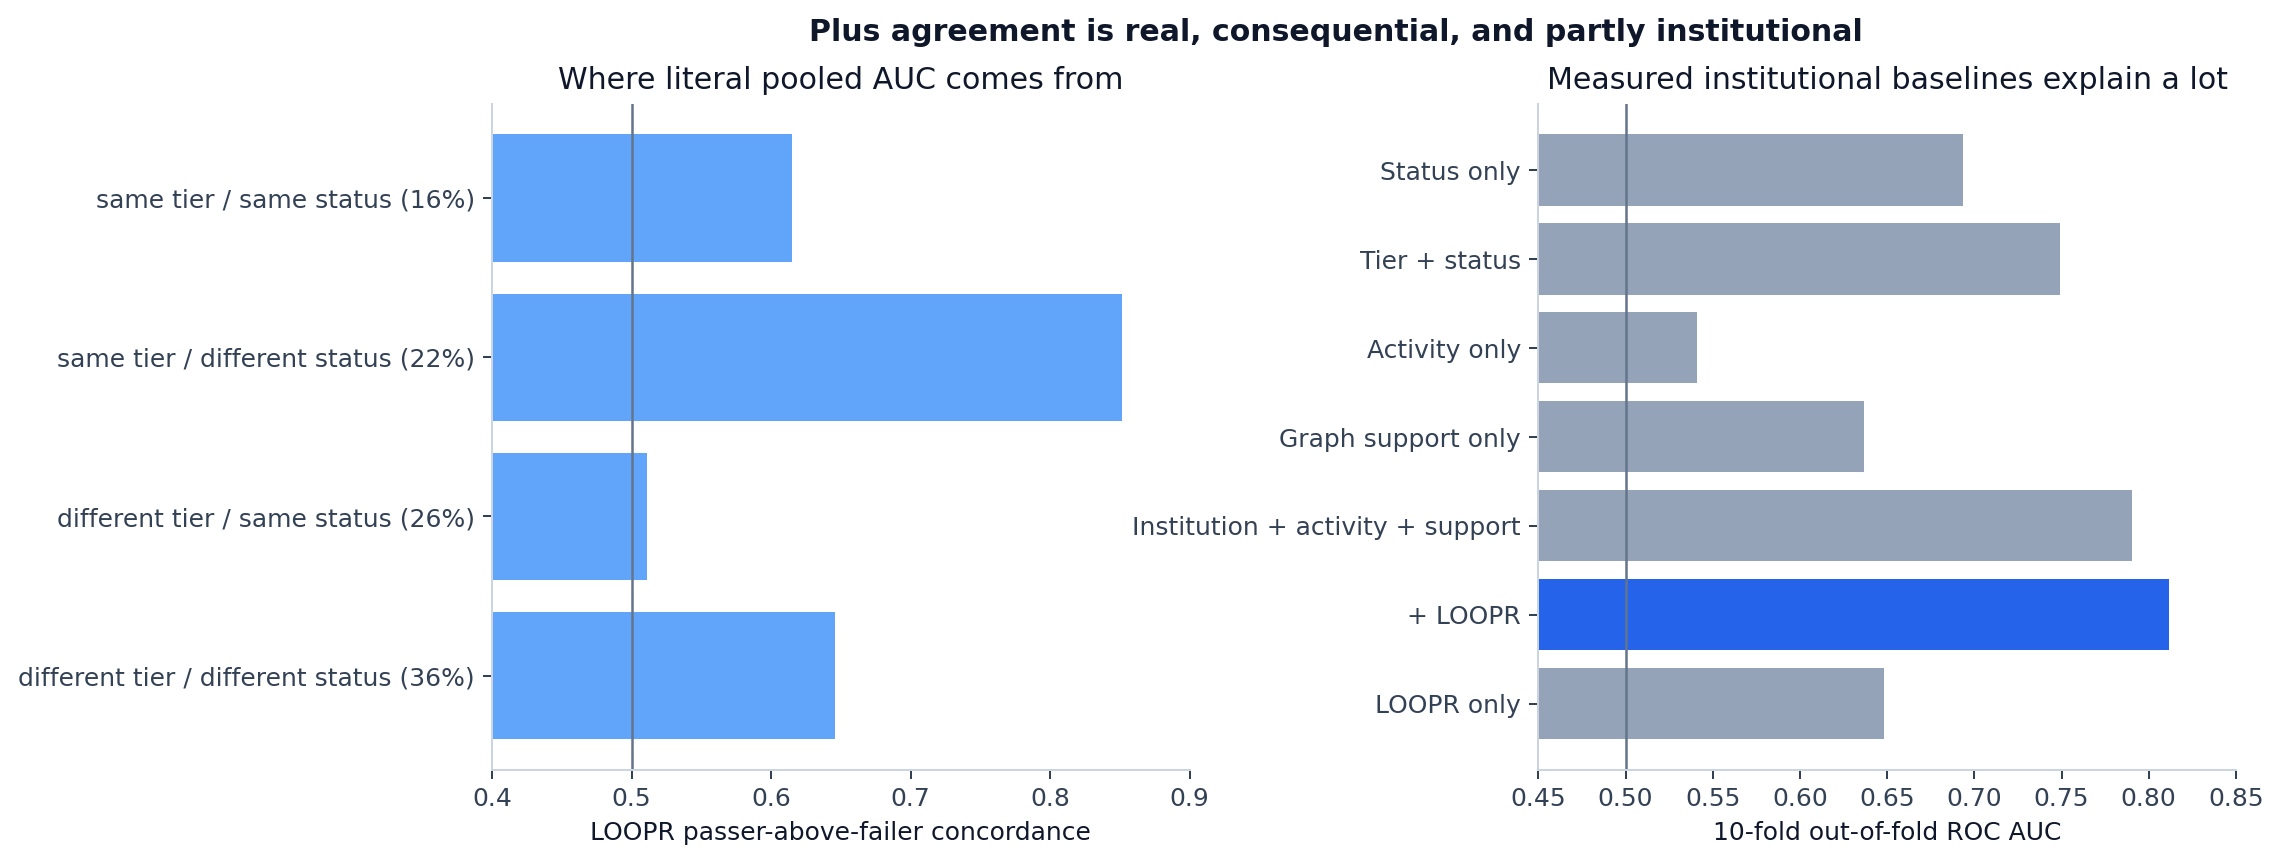

,pair_type,same_tier,same_status,pairs,share_of_all_passer_failer_pairs,loopr_concordance,contribution_to_pooled_auc
0,"same tier, same status",True,True,3500,0.157828,0.615143,0.097087
1,"same tier, different status",True,False,4882,0.220148,0.851495,0.187455
2,"different tier, same status",False,True,5812,0.262085,0.511012,0.133929
3,"different tier, different status",False,False,7982,0.359939,0.645828,0.232459


{'candidate_graph_support': 'all 310 evaluated candidates are in at least the pre-vote 32-core, so graph-support stratification is identical to the full candidate set', 'null_pooled_exceedance_p': 0.004975124378109453, 'null_pooled_mean': 0.5031680645743145, 'null_pooled_q025': 0.43140331890331884, 'null_pooled_q975': 0.5686462842712844, 'null_procedure': 'independent fair-coin result reversal for every pre-vote match; participation, teams, tournaments, timestamps, and volume preserved', 'observed_pooled_auc': 0.6509289321789321, 'repetitions': 200, 'seed': 20260731}


In [6]:
display(Image(filename=str(FIGURES / '05_plus_decomposition.png')))
display(pd.read_csv(TABLES / 'plus_pooled_auc_decomposition.csv'))
print(json.loads((OUTPUT / 'results/pooled_outcome_shuffle.json').read_text()))

## Takeaway

The repository supports a bounded claim about an outcome-derived ranking instrument for established organized-play competitors. Probability quality, operational ranking behavior, institutional convergence, and publication legitimacy remain separate claims.